In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [27]:
# 1. load the dataset
raw = pd.read_csv("superstore_sales.csv")
print(raw.shape)           # (10800, 21)
raw.head()
raw.isnull().sum()         # 806 nulls in most columns, so something is off
raw.iloc[9992:10002, :4]   # look at the rows around the boundary

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date
9992,9993,CA-2018-121258,2/26/2018,3/3/2018
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9996,Chuck Magee,East,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN
9999,Returned,Order ID,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN


In [28]:
# 2.Handle null values, parse order dates, and extract Year-Month.

# keep only genuine order rows (they have an Order Date)
df = raw.dropna(subset=["Order Date"]).copy()

# fix the 11 missing postal codes (all Burlington, Vermont)
df["Postal Code"] = df["Postal Code"].fillna(5401).astype(int).astype(str).str.zfill(5)

# parse dates: the format is month/day/year
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")

# extract time features
df["Year"]      = df["Order Date"].dt.year
df["Month"]     = df["Order Date"].dt.month
df["YearMonth"] = df["Order Date"].dt.to_period("M")

print(df.shape)                       # (9994, 24)
print(df.isnull().sum().sum())        # 0
print(df.duplicated().sum())          # 0

(9994, 24)
0
0


In [29]:
# 3.Group by Product Category, Region, and Customer Segment to compute aggregate Sales & Profit.
def summarize(by):
    out = df.groupby(by).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
    ).sort_values("Sales", ascending=False)
    out["Margin %"] = out["Profit"] / out["Sales"] * 100
    return out

display(summarize("Category"))
display(summarize("Region"))
display(summarize("Segment"))

,Sales,Profit,Orders,Margin %
Category,,,,
Technology,836154.0330,145454.9481,1544,17.395712
Furniture,741999.7953,18451.2728,1764,2.486695
Office Supplies,719047.0320,122490.8008,3742,17.035158


,Sales,Profit,Orders,Margin %
Region,,,,
West,725457.8245,108418.4489,1611,14.944831
East,678781.2400,91522.7800,1401,13.483399
Central,501239.8908,39706.3625,1175,7.921629
South,391721.9050,46749.4303,822,11.934342


,Sales,Profit,Orders,Margin %
Segment,,,,
Consumer,1.161401e+06,134119.2092,2586,11.548050
Corporate,7.061464e+05,91979.1340,1514,13.025506
Home Office,4.296531e+05,60298.6785,909,14.034269


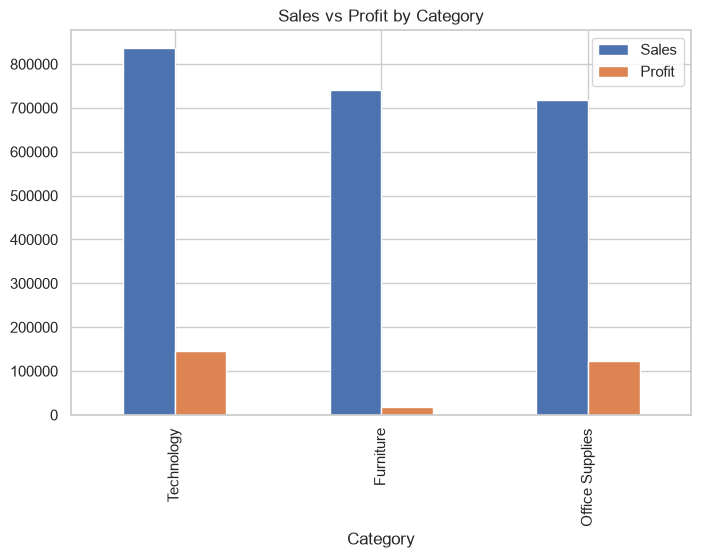

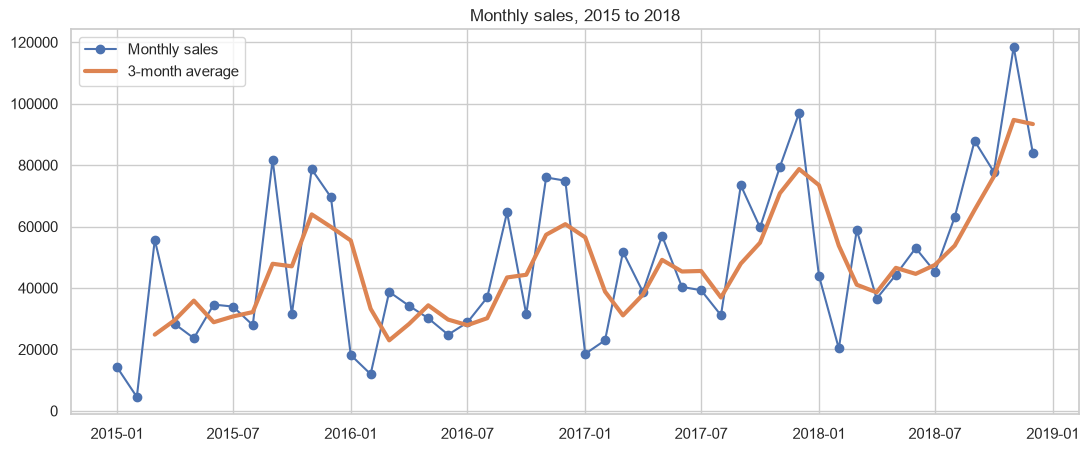

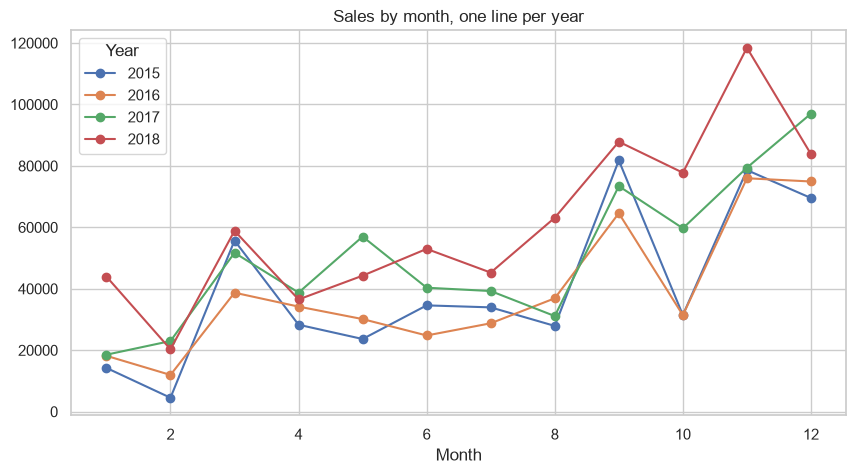

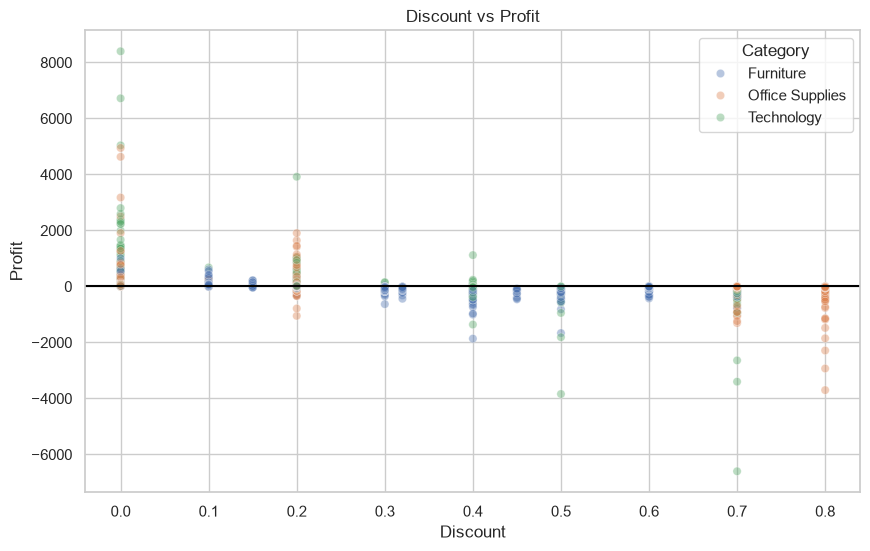

,Sales,Profit,Margin %
Band,,,
0%,1.087908e+06,320987.6032,29.505019
1-10%,5.436935e+04,9029.1770,16.607108
11-20%,7.921529e+05,91756.2975,11.583155
21-30%,1.032267e+05,-10369.2774,-10.045155
31-50%,1.953148e+05,-48447.7273,-24.804950
>50%,6.422874e+04,-76559.0513,-119.197502


Lines >20% discount: 1,393, combined profit: $-135,376
Profit on full-price lines: $320,988
Nov + Dec: 29.5% | Jan + Feb: 6.7%


In [30]:
# 4.

# Sales vs profit by category
cat = summarize("Category").reset_index()
cat.plot(x="Category", y=["Sales", "Profit"], kind="bar", figsize=(8, 5))
plt.title("Sales vs Profit by Category")
plt.show()

# Monthly sales velocity:
monthly = df.groupby("YearMonth")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(13, 5))
plt.plot(monthly.index, monthly, marker="o", label="Monthly sales")
plt.plot(monthly.index, monthly.rolling(3).mean(), lw=3, label="3-month average")
plt.title("Monthly sales, 2015 to 2018")
plt.legend()
plt.show()

# Seasonality by calendar month:
cal = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
cal.plot(figsize=(10, 5), marker="o")
plt.title("Sales by month, one line per year")
plt.show()

# Discount vs profit scatter:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=0.4)
plt.axhline(0, color="black")
plt.title("Discount vs Profit")
plt.show()

df["Discount"].corr(df["Profit"])

# Discount bands
bands = ["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"]
df["Band"] = pd.cut(df["Discount"], [-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0], labels=bands)
band = df.groupby("Band", observed=True).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
band["Margin %"] = band["Profit"] / band["Sales"] * 100
display(band)

deep = df[df["Discount"] > 0.20]
print(f"Lines >20% discount: {len(deep):,}, combined profit: ${deep['Profit'].sum():,.0f}")
print(f"Profit on full-price lines: ${df.loc[df['Discount'] == 0, 'Profit'].sum():,.0f}")

# Seasonality shares
share = cal.sum(axis=1) / cal.values.sum() * 100
print(f"Nov + Dec: {share[[11, 12]].sum():.1f}% | Jan + Feb: {share[[1, 2]].sum():.1f}%")


## Executive Takeaways

### 1. Growth is strong and profitable
Sales grew 51% from 2015 ($484K) to 2018 ($733K), with profit margin steady at 10-13%.

### 2. Sales are highly seasonal
November and December generate 29.5% of all sales, while January and February
together are only 6.7%. **Recommendation:** build inventory before September
and November.

### 3. Discounts above 20% destroy profit
Lines discounted over 20% lost $135K combined. **Recommendation:** cap
discounts at 20% and require approval above it.

### 4. Furniture sells a lot but barely makes money
Furniture has $742K in sales but only a 2.5% margin, versus about 17% for
Technology and Office Supplies. **Recommendation:** review pricing and
discounts on Tables and Bookcases, which lose money.

### 5. Central region underperforms
Central sells more than South ($501K vs $392K) but earns less profit, with a
7.9% margin versus 14.9% in West. **Recommendation:** review Central's
discounting, especially on Furniture.